# 04 — LIBERO 单帧 Planner 几何可行性验证

本 Notebook 复用服务器上 `03_libero_observation_probe.ipynb` 已生成的最新有效 probe，不下载模型、assets 或输出。它用 `/content/.venv_planner/bin/python` 调用 3D HAMSTER，将 `agentview` 的 RGB、米制 depth 和原任务指令转换为 UVD、camera XYZ 与 LIBERO world XYZ。

范围仅限离线单帧几何验证：**不运行低层 policy，不向模拟器发送 action，不修改 SmolVLA，也不声称任务成功。**

In [22]:
from __future__ import annotations

import json
import os
import subprocess
from datetime import datetime, timezone
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("VLA_PROJECT_ROOT", "/content/vla-3d-trajectory-guidance")).resolve()
CONFIG_PATH = PROJECT_ROOT / "configs" / "libero_planner_single_frame.json"
assert CONFIG_PATH.is_file(), f"missing bridge config: {CONFIG_PATH}"
BRIDGE_CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
PLANNER_CONFIG_PATH = PROJECT_ROOT / BRIDGE_CONFIG["planner_config"]
PROBE_CONFIG_PATH = PROJECT_ROOT / BRIDGE_CONFIG["probe_config"]
PLANNER_CONFIG = json.loads(PLANNER_CONFIG_PATH.read_text(encoding="utf-8"))
PROBE_CONFIG = json.loads(PROBE_CONFIG_PATH.read_text(encoding="utf-8"))
SINGLE = BRIDGE_CONFIG["single_frame"]
assert SINGLE["probe_output_root"] == PROBE_CONFIG["probe"]["output_root"]
assert SINGLE["accepted_depth_range_m"] == PROBE_CONFIG["probe"]["accepted_depth_range_m"]
PLANNER_PY = Path(PLANNER_CONFIG["planner"]["env_dir"]) / "bin" / "python"
CHECKPOINT_DIR = Path(PLANNER_CONFIG["planner"]["checkpoint_dir"])
CHECKPOINT_RECORD = PROJECT_ROOT / "outputs" / "environment" / "planner_checkpoint_manifest.json"
PROBE_ROOT = Path(SINGLE["probe_output_root"])
CAMERA_NAME = SINGLE["camera_name"]

def run(command, *, env=None, check=True):
    command = list(map(str, command))
    print("$", " ".join(command), flush=True)
    process = subprocess.Popen(
        command,
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    lines = []
    assert process.stdout is not None
    for line in process.stdout:
        lines.append(line)
        print(line, end="", flush=True)
    returncode = process.wait()
    output = "".join(lines)
    if check and returncode:
        raise subprocess.CalledProcessError(returncode, command, output=output)
    return subprocess.CompletedProcess(command, returncode, stdout=output)

assert PLANNER_PY.is_file(), "Planner 环境不存在，请先运行 01_planner_setup.ipynb"
assert (CHECKPOINT_DIR / "model.safetensors.index.json").is_file(), "Planner checkpoint 不完整"
assert CHECKPOINT_RECORD.is_file(), "缺少 checkpoint revision 记录，请重新运行 01 Notebook 的下载记录单元格"
checkpoint_record = json.loads(CHECKPOINT_RECORD.read_text(encoding="utf-8"))
assert checkpoint_record["requested_revision"] == PLANNER_CONFIG["planner"]["model_revision"]

valid_manifests = []
for manifest_path in PROBE_ROOT.glob("*/observation_manifest.json"):
    try:
        candidate = json.loads(manifest_path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError):
        continue
    camera = candidate.get("cameras", {}).get(CAMERA_NAME, {})
    if candidate.get("valid") is True and camera.get("valid") is True:
        valid_manifests.append((candidate.get("created_at_utc", ""), manifest_path, candidate))
assert valid_manifests, f"在 {PROBE_ROOT} 下没有找到包含 {CAMERA_NAME} 的有效 probe"
_, PROBE_MANIFEST_PATH, PROBE_MANIFEST = max(valid_manifests, key=lambda item: (item[0], str(item[1])))
PROBE_DIR = PROBE_MANIFEST_PATH.parent
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_DIR = Path(SINGLE["output_root"]) / f"{PROBE_DIR.name}_{CAMERA_NAME}_{RUN_ID}"
ENV_RECORD = PROJECT_ROOT / "outputs" / "environment" / f"planner_before_libero_{RUN_ID}.json"
assert not OUTPUT_DIR.exists() or not any(OUTPUT_DIR.iterdir()), f"输出目录非空: {OUTPUT_DIR}"

print(f"Project: {PROJECT_ROOT}")
print(f"Planner interpreter: {PLANNER_PY}")
print(f"Selected probe: {PROBE_DIR}")
print(f"Output: {OUTPUT_DIR}")

Project: /content/vla-3d-trajectory-guidance
Planner interpreter: /content/.venv_planner/bin/python
Selected probe: /content/vla-3d-trajectory-guidance/outputs/libero_observation_probe/libero_spatial_task00_init000_20261101T114213Z
Output: /content/vla-3d-trajectory-guidance/outputs/libero_planner_single_frame/libero_spatial_task00_init000_20261101T114213Z_agentview_20261101T114348Z


## 1. GPU 与输入预检

这里只读取 03 已有产物；不会重新创建 LIBERO 环境，也不会下载 assets。

$ nvidia-smi --query-gpu=name,driver_version,memory.total,memory.free --format=csv,noheader
NVIDIA A100-SXM4-40GB, 580.82.07, 40960 MiB, 40442 MiB
{
  "task": {
    "suite": "libero_spatial",
    "task_id": 0,
    "task_name": "pick_up_the_black_bowl_between_the_plate_and_the_ramekin_and_place_it_on_the_plate",
    "language_instruction": "pick up the black bowl between the plate and the ramekin and place it on the plate",
    "bddl_file": "/content/.venv/lib/python3.12/site-packages/libero/libero/bddl_files/libero_spatial/pick_up_the_black_bowl_between_the_plate_and_the_ramekin_and_place_it_on_the_plate.bddl",
    "bddl_sha256": "9b59eb1287802868ad9bc78d58e6d36d4ba31134e679cfdbdf4b0feb660c959b",
    "init_state_id": 0,
    "init_state_file": "/content/.venv/lib/python3.12/site-packages/libero/libero/init_files/libero_spatial/pick_up_the_black_bowl_between_the_plate_and_the_ramekin_and_place_it_on_the_plate.pruned_init",
    "init_state_sha256": "cbbc73792ce546c9bec181fd328a411d3183074

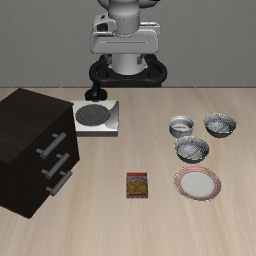

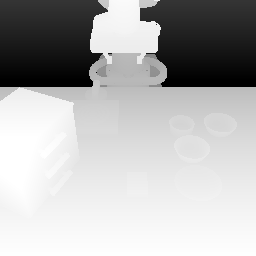

In [23]:
from IPython.display import Image as DisplayImage, display

run(["nvidia-smi", "--query-gpu=name,driver_version,memory.total,memory.free", "--format=csv,noheader"])
camera_record = PROBE_MANIFEST["cameras"][CAMERA_NAME]
rgb_path = Path(camera_record["rgb"]["path"])
depth_preview_path = Path(camera_record["artifacts"]["depth_preview_png"])
assert rgb_path.is_file(), rgb_path
assert depth_preview_path.is_file(), depth_preview_path
print(json.dumps({
    "task": PROBE_MANIFEST["task"],
    "coordinate_conventions": PROBE_MANIFEST["coordinate_conventions"],
    "camera": CAMERA_NAME,
    "probe_valid": PROBE_MANIFEST["valid"],
}, ensure_ascii=False, indent=2))
display(DisplayImage(filename=str(rgb_path)))
display(DisplayImage(filename=str(depth_preview_path)))

## 2. 审计现有 Planner 环境

版本、CUDA、3D HAMSTER commit 都由目标解释器检查。此处不安装或升级任何包。

In [24]:
planner_env = os.environ.copy()
planner_env["HF_HUB_OFFLINE"] = "1"
planner_env["TRANSFORMERS_OFFLINE"] = "1"
python_major_minor = ".".join(PLANNER_CONFIG["python_version"].split(".")[:2])
npp_dir = (
    Path(PLANNER_CONFIG["planner"]["env_dir"])
    / "lib"
    / f"python{python_major_minor}"
    / "site-packages"
    / "nvidia"
    / "npp"
    / "lib"
)
assert list(npp_dir.glob("libnppicc.so*")), f"NVIDIA NPP library not found under {npp_dir}"
current_loader_path = planner_env.get("LD_LIBRARY_PATH", "")
loader_paths = [path for path in current_loader_path.split(os.pathsep) if path]
if str(npp_dir) not in loader_paths:
    planner_env["LD_LIBRARY_PATH"] = str(npp_dir) + (
        os.pathsep + current_loader_path if current_loader_path else ""
    )
print(f"NPP loader path: {npp_dir}")
run([
    PLANNER_PY,
    PROJECT_ROOT / "scripts" / "check_planner_environment.py",
    "--project-root", PROJECT_ROOT,
    "--config", PLANNER_CONFIG_PATH,
    "--gpu-test",
    "--output", ENV_RECORD,
], env=planner_env)
environment_record = json.loads(ENV_RECORD.read_text(encoding="utf-8"))
assert environment_record["provenance"]["planner_repo_commit"] == PLANNER_CONFIG["planner"]["repo_commit"]
assert environment_record["provenance"]["model_revision"] == PLANNER_CONFIG["planner"]["model_revision"]

NPP loader path: /content/.venv_planner/lib/python3.12/site-packages/nvidia/npp/lib
$ /content/.venv_planner/bin/python /content/vla-3d-trajectory-guidance/scripts/check_planner_environment.py --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/planner_colab.json --gpu-test --output /content/vla-3d-trajectory-guidance/outputs/environment/planner_before_libero_20261101T114348Z.json
{
  "schema_version": 1,
  "checked_at_utc": "2026-11-01T11:44:06.891325+00:00",
  "python": {
    "version": "3.12.13",
    "executable": "/content/.venv_planner/bin/python",
    "prefix": "/content/.venv_planner",
    "base_prefix": "/root/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu"
  },
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "versions": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "torchcodec": "0.11.0+cu128",
    "numpy": "2.0.2",
    "nvidia-npp-cu12": "12.4.1.87",
    "transformers": "4.57.6"
  },


## 3. 运行单帧 3D HAMSTER

Planner 只读取 03 的文件产物。输出会保存原始文本、UVD、camera/world XYZ、overlay、耗时和显存。

In [25]:
command = [
    PLANNER_PY,
    PROJECT_ROOT / "scripts" / "run_libero_planner_single_frame.py",
    "--project-root", PROJECT_ROOT,
    "--config", CONFIG_PATH,
    "--probe-dir", PROBE_DIR,
    "--output-dir", OUTPUT_DIR,
    "--camera-name", CAMERA_NAME,
]
inference_process = run(command, env=planner_env, check=False)
if inference_process.returncode not in (0, 2):
    raise subprocess.CalledProcessError(
        inference_process.returncode, command, output=inference_process.stdout
    )
print(f"Inference exit code: {inference_process.returncode}")

$ /content/.venv_planner/bin/python /content/vla-3d-trajectory-guidance/scripts/run_libero_planner_single_frame.py --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/libero_planner_single_frame.json --probe-dir /content/vla-3d-trajectory-guidance/outputs/libero_observation_probe/libero_spatial_task00_init000_20261101T114213Z --output-dir /content/vla-3d-trajectory-guidance/outputs/libero_planner_single_frame/libero_spatial_task00_init000_20261101T114213Z_agentview_20261101T114348Z --camera-name agentview
`torch_dtype` is deprecated! Use `dtype` instead!

Loading checkpoint shards: 100%|██████████| 4/4 [00:05<00:00,  1.34s/it]
The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
{
  "schema_version": 1,
  "valid": true,
  "scope": "single_frame_libero_planner_feasibility_no_policy_no_action_execution",
  "instruction": "pick up the black bowl between the plate 

## 4. 查看结果与几何验收

`planner_minus_scene_depth` 只用于诊断。3D HAMSTER 预测的是自由空间中的 metric depth，不能把像素下方场景表面 depth 当成它的替代值。

{
  "valid": true,
  "instruction": "pick up the black bowl between the plate and the ramekin and place it on the plate",
  "waypoint_count": 3,
  "timing_seconds": {
    "model_load": 9.758232519999979,
    "inference": 6.222632087999955
  },
  "output_validation": {
    "valid": true,
    "errors": [],
    "warnings": [],
    "metrics": {
      "count": 3,
      "u_range": [
        740.0,
        789.0
      ],
      "v_range": [
        448.0,
        640.0
      ],
      "depth_range_m": [
        0.93,
        1.28
      ],
      "accepted_depth_range_m": [
        0.01,
        10.0
      ]
    }
  },
  "geometry_validation": {
    "valid": true,
    "errors": [],
    "warnings": [
      "planner depth differs from the observed surface depth by more than 0.25 m at one or more pixels; this is diagnostic only because 3D waypoints may lie in free space"
    ],
    "metrics": {
      "waypoint_count": 3,
      "projection_roundtrip_max_abs_error": 1.1368683772161603e-13,
      "rigi

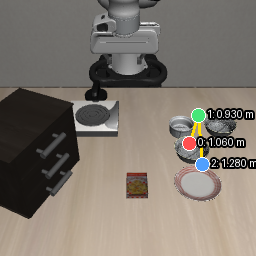

In [26]:
summary_path = OUTPUT_DIR / "run_summary.json"
prediction_path = OUTPUT_DIR / "raw_prediction.json"
assert summary_path.is_file(), summary_path
assert prediction_path.is_file(), prediction_path
summary = json.loads(summary_path.read_text(encoding="utf-8"))
prediction = json.loads(prediction_path.read_text(encoding="utf-8"))
geometry_metrics = (summary.get("geometry_validation") or {}).get("metrics", {})
print(json.dumps({
    "valid": summary["valid"],
    "instruction": summary["instruction"],
    "waypoint_count": summary["waypoint_count"],
    "timing_seconds": summary["timing_seconds"],
    "output_validation": summary["output_validation"],
    "geometry_validation": summary["geometry_validation"],
    "interpretation": summary["interpretation"],
}, ensure_ascii=False, indent=2))
print("\nUVD:", prediction["waypoints_uvd"])
print("Camera XYZ (m):", prediction["camera_xyz_m"])
print("World XYZ (m):", prediction["world_xyz_m"])
overlay_path = summary["artifacts"].get("trajectory_overlay_png")
if overlay_path and Path(overlay_path).is_file():
    display(DisplayImage(filename=str(overlay_path)))

In [27]:
assert inference_process.returncode == 0, "Planner 输出为空、越界或几何检查失败；请查看 raw_prediction.json"
assert summary["valid"] is True
assert summary["output_validation"]["valid"] is True
assert summary["geometry_validation"]["valid"] is True
assert summary["preprocessing"]["valid"] is True
assert summary["waypoint_count"] > 0
assert geometry_metrics["projection_roundtrip_max_abs_error"] <= SINGLE["max_projection_roundtrip_error"]
assert prediction["planner"]["repo_commit"] == PLANNER_CONFIG["planner"]["repo_commit"]
assert prediction["planner"]["model_revision"] == PLANNER_CONFIG["planner"]["model_revision"]
for key in ("waypoints_uvd_csv", "waypoints_camera_xyz_csv", "waypoints_world_xyz_csv", "trajectory_overlay_png"):
    artifact = summary["artifacts"][key]
    assert artifact and Path(artifact).is_file(), (key, artifact)
cache_record = summary["artifacts"].get("trajectory_cache_record")
assert cache_record and Path(cache_record).is_dir(), cache_record
print("LIBERO 单帧 Planner UVD → camera/world XYZ 几何验收通过。未运行 policy 或 simulator action。")

LIBERO 单帧 Planner UVD → camera/world XYZ 几何验收通过。未运行 policy 或 simulator action。


## 5. 可选：CPU Mock Planner 全链路

该模式不加载 3D HAMSTER、不使用 GPU，并把所有结果明确写到 `outputs/mock_planner/`。它覆盖合法、空轨迹、U/V 越界和无效 depth；Mock 通过不代表真实 Planner 通过。

In [28]:
RUN_CPU_MOCK = True  # 本地/Colab 离线开发时手动改为 True
if RUN_CPU_MOCK:
    import sys
    mock_python = Path("/content/.venv/bin/python")
    if not mock_python.is_file():
        mock_python = Path(sys.executable)
    mock_output = PROJECT_ROOT / "outputs" / "mock_planner" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    run([
        mock_python,
        PROJECT_ROOT / "scripts" / "run_mock_planner_validation.py",
        "--project-root", PROJECT_ROOT,
        "--output-dir", mock_output,
    ])
    print(f"Mock-only outputs: {mock_output}")
else:
    print("CPU Mock 未运行；这不会影响上面的真实 Planner 流程。")

$ /content/.venv/bin/python /content/vla-3d-trajectory-guidance/scripts/run_mock_planner_validation.py --project-root /content/vla-3d-trajectory-guidance --output-dir /content/vla-3d-trajectory-guidance/outputs/mock_planner/20261101T114512Z
{
  "schema_version": 1,
  "scope": "cpu_mock_planner_validation_no_real_model_no_gpu",
  "mock": true,
  "all_cases_passed": true,
  "cases": [
    {
      "schema_version": 1,
      "created_at_utc": "2026-11-01T11:45:12.825018+00:00",
      "scope": "cpu_mock_planner_validation_no_real_model_no_gpu",
      "mock": true,
      "mock_model_id": "mock/fixed-uvd-v1",
      "case": "valid",
      "expected_valid": true,
      "actual_valid": true,
      "case_passed": true,
      "output_validation": {
        "valid": true,
        "errors": [],
        "warnings": [],
        "metrics": {
          "count": 3,
          "u_range": [
            350.0,
            650.0
          ],
          "v_range": [
            460.0,
            540.0
        